# Perceptron

The simplest neural unit and the ancestor of logistic regression, SVMs and the MLP. It draws a line `w·x + b = 0`; whenever a sample lands on the wrong side, push the line toward it:

```
if y * (w·x + b) <= 0:      # y in {-1, +1}
    w += lr * y * x
    b += lr * y
```

- **Guaranteed to converge** if the classes are linearly separable (the perceptron convergence theorem), after which `errors_` hits 0.
- **Never converges** otherwise — XOR is the classic counter-example, which is what motivated multi-layer networks (`26_neural_network`).
- It finds *a* separating line, not the widest-margin one (that is `16_svm`), and gives no probabilities (that is `09_logistic_regression`).

Binary only; labels can be any two values.

## Usage

```python
# (the class is defined in the Implementation section below)

model = Perceptron(epochs=100).fit(X_train, y_train)
preds = model.predict(X_test)
print(model.errors_)    # mistakes per epoch
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class Perceptron:
    """The original linear classifier (Rosenblatt, 1958). For every misclassified sample, nudge the
    boundary toward it:  w += lr * y * x.  Converges only if the classes are linearly separable.

    Binary; labels can be any two values."""

    def __init__(self, lr=1.0, epochs=100, random_state=0):
        self.lr = lr
        self.epochs = epochs
        self.random_state = random_state
        self.classes_ = None
        self.weights = None
        self.bias = 0.0
        self.errors_ = []  # misclassifications per epoch; ends at 0 once converged

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        self.classes_, y_enc = np.unique(y, return_inverse=True)
        if len(self.classes_) != 2:
            raise ValueError("Perceptron is binary: needs exactly 2 classes")
        y_pm = 2 * y_enc - 1  # {0, 1} -> {-1, +1}

        rng = np.random.default_rng(self.random_state)
        self.weights = np.zeros(X.shape[1])
        self.bias = 0.0
        self.errors_ = []
        for _ in range(self.epochs):
            errors = 0
            for i in rng.permutation(len(X)):
                if y_pm[i] * (X[i] @ self.weights + self.bias) <= 0:  # wrong side (or on the line)
                    self.weights += self.lr * y_pm[i] * X[i]
                    self.bias += self.lr * y_pm[i]
                    errors += 1
            self.errors_.append(errors)
            if errors == 0:
                break
        return self

    def decision_function(self, X):
        return np.asarray(X, dtype=float) @ self.weights + self.bias

    def predict(self, X):
        return self.classes_[(self.decision_function(X) > 0).astype(int)]

## See it work

### 1. The boundary, epoch by epoch

Linearly separable data (but with the classes fairly close). Each misclassified point nudges the line toward itself (`w += y·x`). The line wobbles for a few passes and then settles; once a full pass has no mistakes it never moves again.

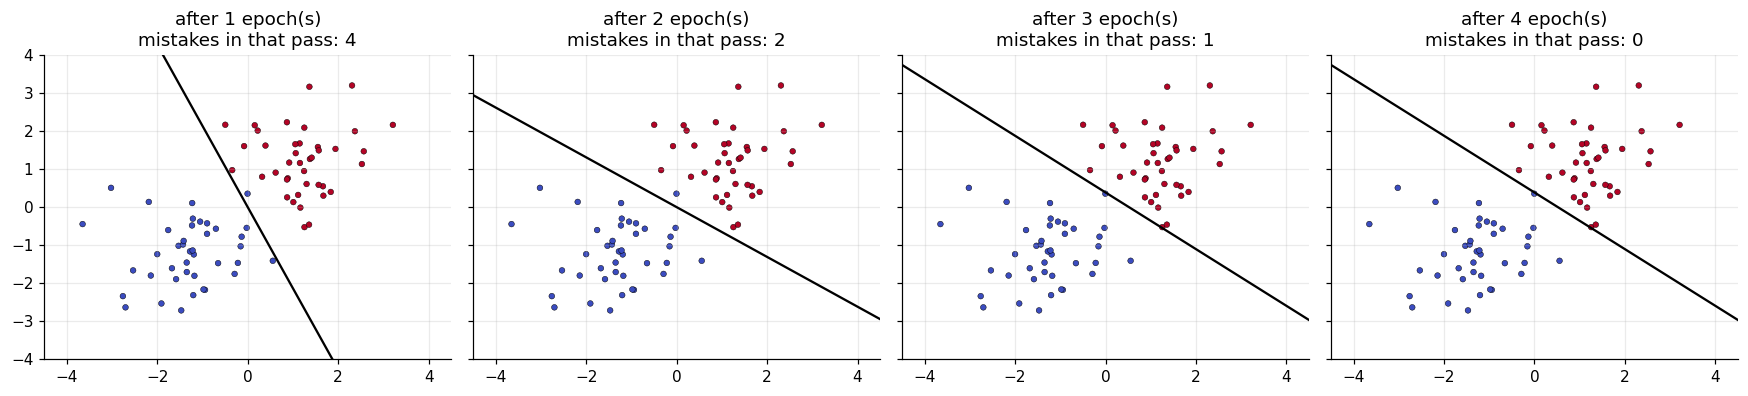

In [3]:
from sklearn.datasets import make_blobs

X, y = make_blobs(n_samples=80, centers=[[-1.3, -1.3], [1.3, 1.3]], cluster_std=0.75, random_state=8)
xs = np.linspace(-6, 6, 100)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.7), sharex=True, sharey=True)
for ax, ep in zip(axes, [1, 2, 3, 4]):
    p = Perceptron(epochs=ep).fit(X, y)
    ax.scatter(*X.T, c=y, cmap="coolwarm", s=14, edgecolor="k", linewidth=0.3)
    ax.plot(xs, -(p.weights[0] * xs + p.bias) / p.weights[1], "k"); ax.set(title=f"after {ep} epoch(s)\nmistakes in that pass: {p.errors_[-1]}", ylim=(-4, 4), xlim=(-4.5, 4.5))
plt.tight_layout(); plt.show()

### 2. Convergence vs non-convergence

On separable data the number of mistakes per epoch falls to **zero** (the perceptron convergence theorem guarantees this). On data no straight line can split (XOR), it never gets there and keeps flailing, so the error count never reaches 0.

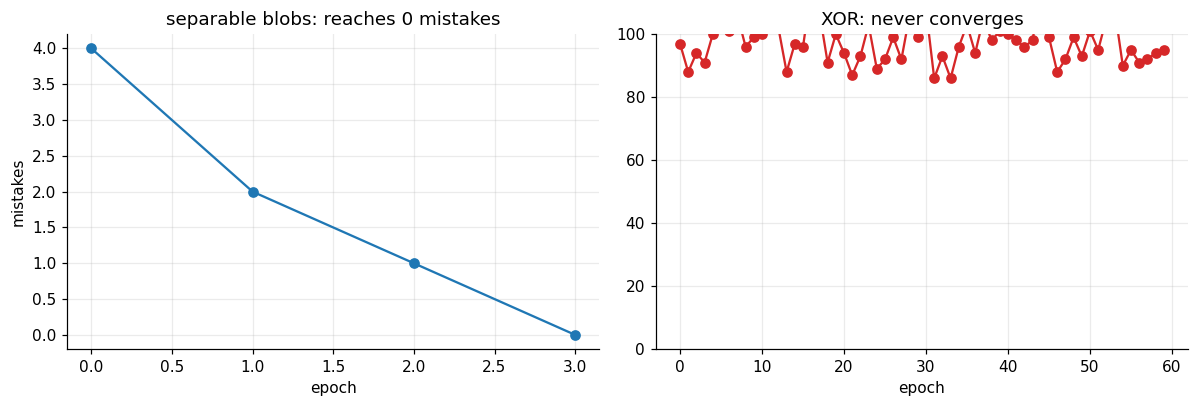

In [4]:
rng = np.random.default_rng(0)
Xx = rng.uniform(-1, 1, size=(200, 2)); yx = ((Xx[:, 0] > 0) ^ (Xx[:, 1] > 0)).astype(int)      # XOR
sep = Perceptron(epochs=60).fit(X, y); xor = Perceptron(epochs=60).fit(Xx, yx)
fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3.8))
a.plot(sep.errors_, "o-"); a.set(title="separable blobs: reaches 0 mistakes", xlabel="epoch", ylabel="mistakes")
b.plot(xor.errors_, "o-", color="C3"); b.set(title="XOR: never converges", xlabel="epoch", ylim=(0, 100))
plt.tight_layout(); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [5]:
from sklearn.datasets import make_blobs
from sklearn.linear_model import Perceptron as SklearnPerceptron
from sklearn.model_selection import train_test_split

X, y = make_blobs(n_samples=300, centers=[[-3, -3], [3, 3]], cluster_std=1.0, random_state=0)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=0)

ours = Perceptron(epochs=100).fit(X_train, y_train)
theirs = SklearnPerceptron(max_iter=1000, tol=None, random_state=0).fit(X_train, y_train)

acc_ours = (ours.predict(X_test) == y_test).mean()
acc_theirs = (theirs.predict(X_test) == y_test).mean()
print("test accuracy: ours=%.4f sklearn=%.4f" % (acc_ours, acc_theirs))
print("mistakes per epoch:", ours.errors_)  # reaches 0 = converged (data is linearly separable)
assert ours.errors_[-1] == 0
assert abs(acc_ours - acc_theirs) < 0.05

test accuracy: ours=1.0000 sklearn=1.0000
mistakes per epoch: [1, 0]


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [6]:
import numpy as np


def test_converges_on_separable_data_with_string_labels():
    rng = np.random.default_rng(0)
    X = np.vstack([rng.normal(-3, 0.6, (60, 2)), rng.normal(3, 0.6, (60, 2))])
    y = np.array(["a"] * 60 + ["b"] * 60)
    model = Perceptron().fit(X, y)
    assert model.errors_[-1] == 0  # converged
    assert (model.predict(X) == y).all()


def test_cannot_learn_xor():
    # the classic limit: no single line separates XOR, so it never converges
    X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
    y = np.array([0, 1, 1, 0])
    model = Perceptron(epochs=200).fit(X, y)
    assert model.errors_[-1] > 0
    assert (model.predict(X) == y).mean() < 1.0


def test_rejects_multiclass():
    try:
        Perceptron().fit(np.zeros((3, 2)), np.array([0, 1, 2]))
    except ValueError:
        return
    raise AssertionError("expected ValueError")

In [7]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_converges_on_separable_data_with_string_labels
PASS test_cannot_learn_xor
PASS test_rejects_multiclass

all 3 tests passed


## Takeaways

- **Use it for** understanding, not production: it is the ancestor of logistic regression, SVMs and neural nets, and the simplest online learner (update only on mistakes).
- **Guarantee:** if the data are linearly separable it converges in a finite number of updates (bounded by `(R/γ)²`). If not, it never settles. It also returns *some* separating line, not the best one (an SVM picks the maximum-margin line, `16_svm`).
- **Limit:** no probabilities; one neuron cannot learn XOR, which is why we stack them (`26_neural_network`).
- **Interview line:** *"On a mistake, `w += y·x`. Converges iff separable."*